Implement cross-validation with different folds by designing custom k-fold and stratified split mechanisms, ensuring balanced class representation, and analyzing variance in model performance across iterations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).reset_index(drop=True)

X = df[features].to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", X.shape)
print("Class distribution:", pd.Series(y).value_counts().to_dict())

Dataset shape: (79, 5)
Class distribution: {1: 61, 0: 18}


In [2]:
def custom_kfold(n_samples, k=5, seed=42):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(n_samples)
    folds = np.array_split(indices, k)

    for i in range(k):
        test_idx = folds[i]
        train_idx = np.concatenate([
            folds[j] for j in range(k) if j != i
        ])
        yield train_idx, test_idx


def custom_stratified_kfold(y, k=5, seed=42):
    rng = np.random.default_rng(seed)
    fold_parts = [[] for _ in range(k)]

    for cls in np.unique(y):
        class_indices = np.where(y == cls)[0]
        rng.shuffle(class_indices)

        for fold_id, part in enumerate(np.array_split(class_indices, k)):
            fold_parts[fold_id].extend(part.tolist())

    for i in range(k):
        test_idx = np.array(sorted(fold_parts[i]))
        train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
        yield train_idx, test_idx


k = 5

if pd.Series(y).value_counts().min() < k:
    raise ValueError("Reduce k because a class has fewer than k samples.")

print("Custom split functions created.")

Custom split functions created.


In [3]:
def create_model():
    return make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            class_weight="balanced"
        )
    )


results = []

split_methods = {
    "K-Fold": custom_kfold(len(y), k=5, seed=42),
    "Stratified K-Fold": custom_stratified_kfold(y, k=5, seed=42)
}

for method, splits in split_methods.items():
    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        model = create_model()
        model.fit(X[train_idx], y[train_idx])

        pred = model.predict(X[test_idx])

        results.append({
            "Method": method,
            "Fold": fold,
            "Accuracy": accuracy_score(y[test_idx], pred),
            "F1 Score": f1_score(
                y[test_idx], pred, zero_division=0
            ),
            "Test Class 1 Rate": y[test_idx].mean()
        })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

           Method  Fold  Accuracy  F1 Score  Test Class 1 Rate
           K-Fold     1    0.6250    0.7000             0.7500
           K-Fold     2    0.7500    0.8571             0.8750
           K-Fold     3    0.7500    0.8462             0.7500
           K-Fold     4    0.7500    0.8333             0.8125
           K-Fold     5    0.8000    0.8571             0.6667
Stratified K-Fold     1    0.8235    0.8889             0.7647
Stratified K-Fold     2    0.8750    0.9091             0.7500
Stratified K-Fold     3    0.8125    0.8800             0.7500
Stratified K-Fold     4    0.7333    0.8182             0.8000
Stratified K-Fold     5    0.7333    0.8333             0.8000


In [4]:
summary = results_df.groupby("Method").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_F1=("F1 Score", "mean"),
    Std_F1=("F1 Score", "std")
)

print(summary.round(4))

                   Mean_Accuracy  Std_Accuracy  Mean_F1  Std_F1
Method                                                         
K-Fold                    0.7350        0.0652   0.8188  0.0671
Stratified K-Fold         0.7955        0.0615   0.8659  0.0385


In [5]:
balance_results = []

for method, split_function in [
    ("K-Fold", lambda: custom_kfold(len(y), 5, 42)),
    ("Stratified K-Fold", lambda: custom_stratified_kfold(y, 5, 42))
]:
    for fold, (_, test_idx) in enumerate(split_function(), start=1):
        counts = pd.Series(y[test_idx]).value_counts().to_dict()

        balance_results.append({
            "Method": method,
            "Fold": fold,
            "Class 0": counts.get(0, 0),
            "Class 1": counts.get(1, 0),
            "Positive Rate": y[test_idx].mean()
        })

balance_df = pd.DataFrame(balance_results)
print(balance_df.to_string(index=False))

           Method  Fold  Class 0  Class 1  Positive Rate
           K-Fold     1        4       12       0.750000
           K-Fold     2        2       14       0.875000
           K-Fold     3        4       12       0.750000
           K-Fold     4        3       13       0.812500
           K-Fold     5        5       10       0.666667
Stratified K-Fold     1        4       13       0.764706
Stratified K-Fold     2        4       12       0.750000
Stratified K-Fold     3        4       12       0.750000
Stratified K-Fold     4        3       12       0.800000
Stratified K-Fold     5        3       12       0.800000


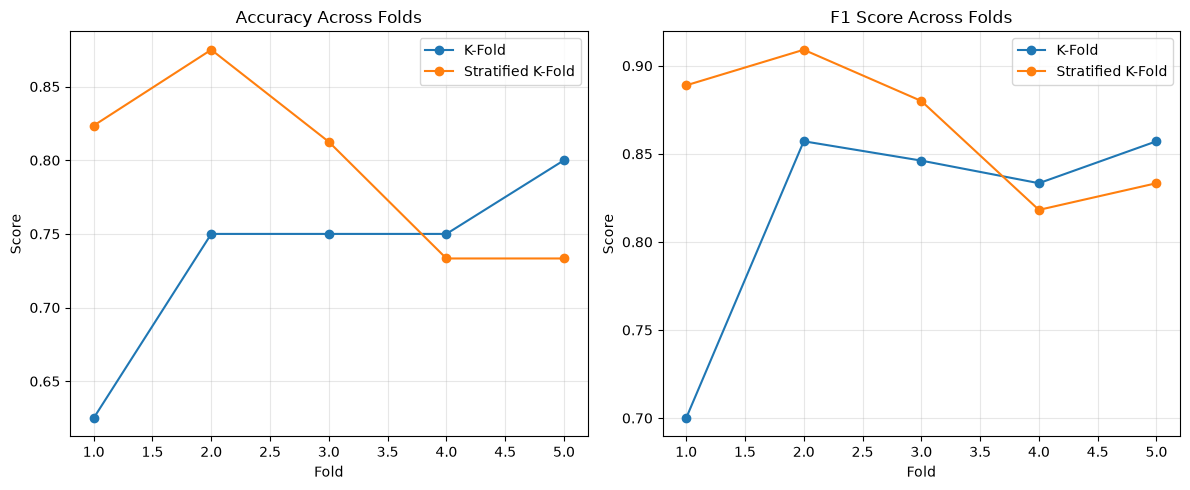

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for method, group in results_df.groupby("Method"):
    axes[0].plot(
        group["Fold"], group["Accuracy"],
        marker="o", label=method
    )
    axes[1].plot(
        group["Fold"], group["F1 Score"],
        marker="o", label=method
    )

axes[0].set_title("Accuracy Across Folds")
axes[1].set_title("F1 Score Across Folds")

for ax in axes:
    ax.set_xlabel("Fold")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
print("Cross-Validation Summary")
print(summary.round(4))

for method, group in results_df.groupby("Method"):
    print(f"\n{method}")
    print("Accuracy variance:", round(group["Accuracy"].var(), 6))
    print("F1 variance:", round(group["F1 Score"].var(), 6))

print("\nConclusion:")
print("Lower standard deviation indicates more consistent performance.")
print("Stratified K-fold aims to preserve class proportions in every fold.")
print("Cross-Validation Summary")
print(summary.round(4))

for method, group in results_df.groupby("Method"):
    print(f"\n{method}")
    print("Accuracy variance:", round(group["Accuracy"].var(), 6))
    print("F1 variance:", round(group["F1 Score"].var(), 6))

print("\nConclusion:")
print("Lower standard deviation indicates more consistent performance.")
print("Stratified K-fold aims to preserve class proportions in every fold.")

Cross-Validation Summary
                   Mean_Accuracy  Std_Accuracy  Mean_F1  Std_F1
Method                                                         
K-Fold                    0.7350        0.0652   0.8188  0.0671
Stratified K-Fold         0.7955        0.0615   0.8659  0.0385

K-Fold
Accuracy variance: 0.00425
F1 variance: 0.004503

Stratified K-Fold
Accuracy variance: 0.003781
F1 variance: 0.001483

Conclusion:
Lower standard deviation indicates more consistent performance.
Stratified K-fold aims to preserve class proportions in every fold.
Cross-Validation Summary
                   Mean_Accuracy  Std_Accuracy  Mean_F1  Std_F1
Method                                                         
K-Fold                    0.7350        0.0652   0.8188  0.0671
Stratified K-Fold         0.7955        0.0615   0.8659  0.0385

K-Fold
Accuracy variance: 0.00425
F1 variance: 0.004503

Stratified K-Fold
Accuracy variance: 0.003781
F1 variance: 0.001483

Conclusion:
Lower standard deviation ind